In [1]:
%pip install -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [6]:
import os
from pathlib import Path
from dotenv import load_dotenv
import numpy as np
import random
import pandas as pd
import matplotlib.pyplot as plt

load_dotenv(Path(".env"))
TEAM_ID = 3
BASE_SEED = 2026
REPETITIONS = 10
LEARNING_RATES = (0.4, 0.1, 0.01)
WEIGHT_INTERVALS = ((-100.0, 100.0), (-0.5, 0.5))
MAX_EPOCHS = 100000 

In [7]:
print('Dados carregados para os experimentos:')
os.environ["DATASET_PATH_2"] = f".data/data{TEAM_ID}20262.txt"
DATASET_PATH = Path(os.getenv("DATASET_PATH_2"))
if not DATASET_PATH.is_file():
    raise FileNotFoundError(f"Arquivo da equipe {TEAM_ID} não encontrado: {DATASET_PATH}")
data = np.load(DATASET_PATH, allow_pickle=False).squeeze()
if data.ndim != 2 or data.shape[1] != 3:
    raise ValueError("O dataset deve conter linhas (x1, x2, yd).")
if not np.isfinite(data).all() or not np.isin(data[:, -1], [0, 1]).all():
    raise ValueError("Dados inválidos: entradas finitas e classes 0/1 são necessárias.")
print(f"Arquivo: {DATASET_PATH} | Tipo: {type(data).__name__} | Dimensões: {data.shape}")
print("Primeiros cinco exemplos:\n", data[:5])
print("Contagem das classes:", dict(zip(*np.unique(data[:, -1].astype(int), return_counts=True))))

Dados carregados para os experimentos:
Arquivo: .data\data320262.txt | Tipo: ndarray | Dimensões: (1000, 3)
Primeiros cinco exemplos:
 [[ 146.2613139    56.98229034    1.        ]
 [ 527.3004796   623.38553402    1.        ]
 [  20.4577104   558.6793448     1.        ]
 [ 592.22660892  189.51000868    1.        ]
 [-182.84390621  342.55287961    1.        ]]
Contagem das classes: {np.int64(0): np.int64(346), np.int64(1): np.int64(654)}


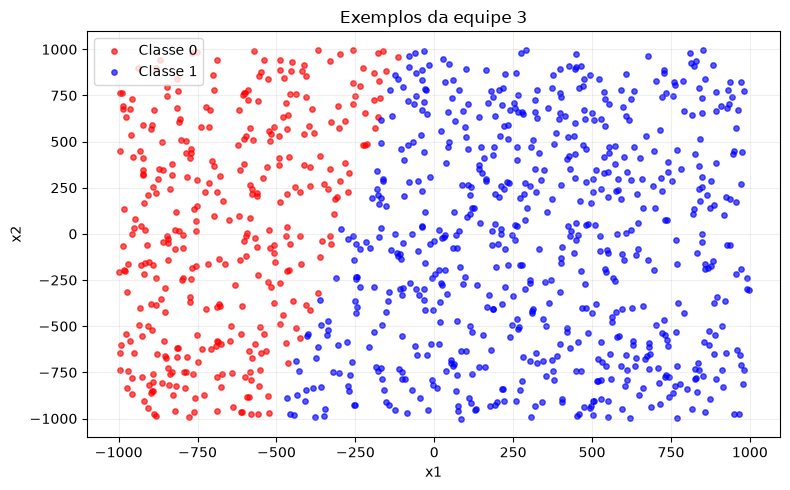

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))
for label, color in ((0, "red"), (1, "blue")):
    points = data[data[:, -1] == label]
    ax.scatter(points[:, 0], points[:, 1], color=color, label=f"Classe {label}", s=15, alpha=0.65)
ax.set(xlabel="x1", ylabel="x2", title=f"Exemplos da equipe {TEAM_ID}")
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [9]:
class Neuron:
    def __init__(self, dataset, learning_rate=0.1, weight_interval=(-0.5, 0.5), seed=None):
        self.dataset = np.asarray(dataset, dtype=float)
        self.X = self.dataset[:, :-1]
        self.Yd = self.dataset[:, -1].astype(int)
        self.Yp = np.empty(0, dtype=int)
        self.weights = np.zeros(self.X.shape[1], dtype=float)
        self.bias = 0.0
        self.learning_rate = learning_rate
        self.weight_interval = weight_interval
        self.rng = random.Random(seed)
        self.w_adjust_count = 0
        self.epochs = 0
        self.w_changes = []

    def threshold(self, inputs, weights, bias):
        if len(inputs) != len(weights):
            raise ValueError("Entradas e pesos devem ter a mesma dimensão.")
        return int(np.dot(inputs, weights) + bias >= 0)

    def init_weights(self):
        low, high = self.weight_interval
        self.weights = np.array([self.rng.uniform(low, high) for _ in range(self.X.shape[1])])
        self.bias = self.rng.uniform(low, high)
        print(f"Vetor inicial de pesos: {self.weights}; bias: {self.bias:.6f}")

    def adjust_weights(self, inputs, weights, error):
        return weights + self.learning_rate * error * inputs

    def train(self, inputs, targets, max_epochs=MAX_EPOCHS):
        self.w_adjust_count, self.epochs = 0, 0
        self.w_changes = []
        self.init_weights()
        for epoch in range(1, max_epochs + 1):
            # Avança pelos exemplos corretos em bloco, preservando a ordem online.
            position = 0
            while position < len(inputs):
                predictions = (inputs[position:] @ self.weights + self.bias >= 0).astype(int)
                mistakes = np.flatnonzero(predictions != targets[position:])
                if mistakes.size == 0:
                    break
                position += int(mistakes[0])
                xi, yi = inputs[position], targets[position]
                error = int(yi) - self.threshold(xi, self.weights, self.bias)
                self.weights = self.adjust_weights(xi, self.weights, error)
                self.bias += self.learning_rate * error
                self.w_adjust_count += 1
                position += 1
            self.epochs = epoch
            self.w_changes.append(np.append(self.weights, self.bias).copy())
            self.Yp = (np.asarray(inputs) @ self.weights + self.bias >= 0).astype(int)
            if np.array_equal(self.Yp, targets):
                return
        raise RuntimeError(f"Não convergiu em {max_epochs} épocas; execução não incluída nos resultados.")

    def execute(self):
        self.train(self.X, self.Yd)
        print(f"Número total de ajustes no vetor de pesos: {self.w_adjust_count}")
        print(f"Número de épocas até a convergência: {self.epochs}")
        return self

In [10]:
print('Treinamento: seis configurações, com dez repetições cada.')
records = []
for learning_rate in LEARNING_RATES:
    for interval in WEIGHT_INTERVALS:
        config = f"η={learning_rate:g} | ({interval[0]:g}, {interval[1]:g})"
        for repetition in range(1, REPETITIONS + 1):
            print(f"\n{config} — repetição {repetition}/{REPETITIONS}")
            neuron = Neuron(data, learning_rate, interval, seed=BASE_SEED + repetition)
            neuron.execute()
            errors = int(np.count_nonzero(neuron.Yp != neuron.Yd))
            assert errors == 0, "A execução deve convergir antes de ser registrada."
            records.append({"configuracao": config, "taxa": learning_rate,
                            "intervalo": str(interval), "repeticao": repetition,
                            "semente": BASE_SEED + repetition, "ajustes": neuron.w_adjust_count,
                            "epocas": neuron.epochs, "erros_finais": errors,
                            "w1": neuron.weights[0], "w2": neuron.weights[1], "bias": neuron.bias})
results = pd.DataFrame(records)
assert len(results) == 60
assert (results.groupby("configuracao").size() == REPETITIONS).all()
print(f"\nConcluídos: {len(results)} treinamentos; todos com zero erros finais.")

Treinamento: seis configurações, com dez repetições cada.

η=0.4 | (-100, 100) — repetição 1/10
Vetor inicial de pesos: [-78.33336454  -7.18959111]; bias: -97.287106
Número total de ajustes no vetor de pesos: 335868
Número de épocas até a convergência: 2852

η=0.4 | (-100, 100) — repetição 2/10
Vetor inicial de pesos: [-28.97842999 -64.24789323]; bias: -94.439539
Número total de ajustes no vetor de pesos: 122994
Número de épocas até a convergência: 832

η=0.4 | (-100, 100) — repetição 3/10
Vetor inicial de pesos: [44.01837512 -3.23172063]; bias: 84.764214
Número total de ajustes no vetor de pesos: 260600
Número de épocas até a convergência: 2075

η=0.4 | (-100, 100) — repetição 4/10
Vetor inicial de pesos: [-42.850993   -25.59631779]; bias: 0.181094
Número total de ajustes no vetor de pesos: 407088
Número de épocas até a convergência: 3692

η=0.4 | (-100, 100) — repetição 5/10
Vetor inicial de pesos: [ 32.82132026 -33.60580002]; bias: 54.826086
Número total de ajustes no vetor de pesos

In [11]:
summary = results.groupby("configuracao", sort=False).agg(
    taxa=("taxa", "first"), intervalo=("intervalo", "first"),
    media_ajustes=("ajustes", "mean"), desvio_ajustes=("ajustes", "std"),
    min_epocas=("epocas", "min"), max_epocas=("epocas", "max"),
    mediana_ajustes=("ajustes", "median")
).reset_index()
table = pd.DataFrame({
    "Taxa de aprendizado": summary.taxa,
    "Intervalo de pesos": summary.intervalo,
    "Qtde ajustes (média ± DP)": [f"{m:.2f} ± {s:.2f}" for m, s in zip(summary.media_ajustes, summary.desvio_ajustes)],
    "Min épocas": summary.min_epocas,
    "Max épocas": summary.max_epocas,
})
print(table.to_string(index=False))

 Taxa de aprendizado Intervalo de pesos Qtde ajustes (média ± DP)  Min épocas  Max épocas
                0.40    (-100.0, 100.0)      266567.60 ± 82383.23         832        3692
                0.40        (-0.5, 0.5)      257964.30 ± 86534.71         829        3697
                0.10    (-100.0, 100.0)     298464.80 ± 119780.45        1545        5091
                0.10        (-0.5, 0.5)     287682.80 ± 105257.32        1542        5015
                0.01    (-100.0, 100.0)     316980.10 ± 128727.91        1452        7056
                0.01        (-0.5, 0.5)      302669.90 ± 83028.60         742        3667


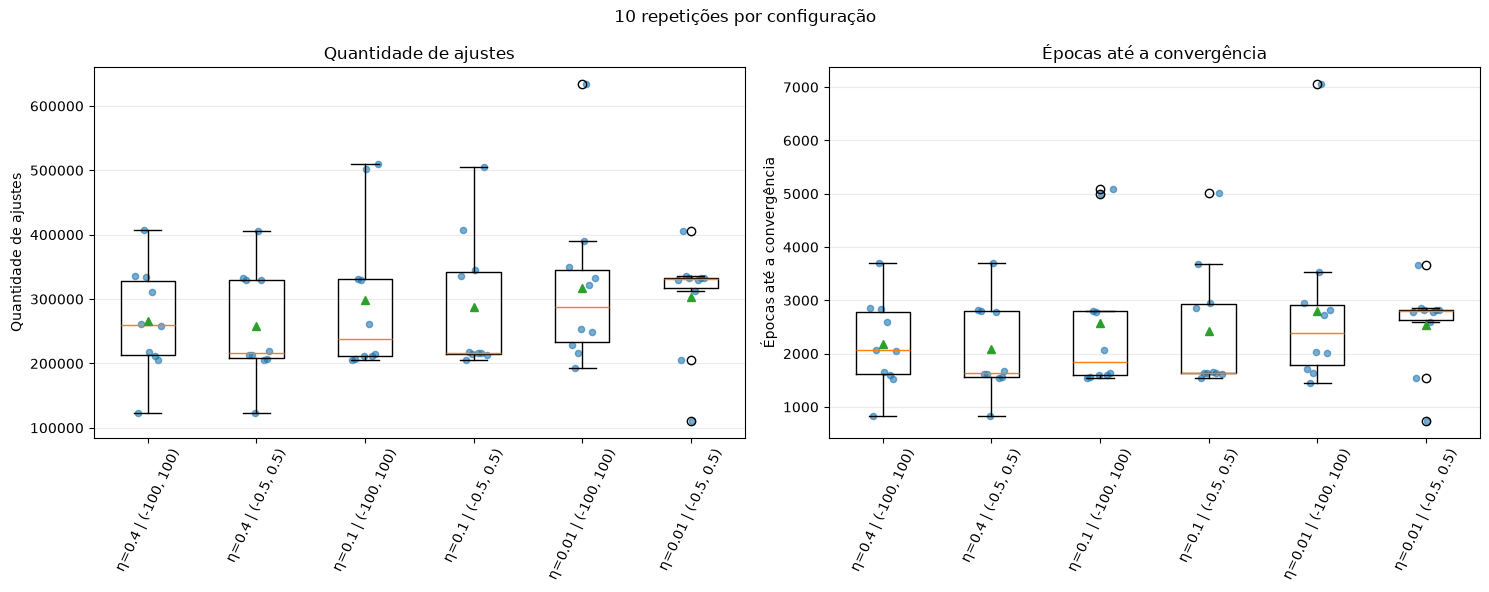

In [12]:
labels = summary.configuracao.tolist()
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, metric, title in zip(axes, ("ajustes", "epocas"), ("Quantidade de ajustes", "Épocas até a convergência")):
    groups = [results.loc[results.configuracao == label, metric].to_numpy() for label in labels]
    ax.boxplot(groups, tick_labels=labels, showmeans=True)
    for position, values in enumerate(groups, start=1):
        offsets = np.linspace(-0.12, 0.12, len(values))
        ax.scatter(position + offsets, values, s=20, alpha=0.6, color="tab:blue")
    ax.set(title=title, ylabel=title)
    ax.tick_params(axis="x", rotation=65)
    ax.grid(axis="y", alpha=0.25)
fig.suptitle("10 repetições por configuração")
plt.tight_layout()
plt.show()

In [13]:
print('Comparação pelo número médio de ajustes:')
best = summary.loc[summary.media_ajustes.idxmin()]
worst = summary.loc[summary.media_ajustes.idxmax()]
print(f"Menor média de ajustes: {best.configuracao} ({best.media_ajustes:.2f} ± {best.desvio_ajustes:.2f}).")
print(f"Maior média de ajustes: {worst.configuracao} ({worst.media_ajustes:.2f} ± {worst.desvio_ajustes:.2f}).")
print(f"Razão entre a maior e a menor média: {worst.media_ajustes / best.media_ajustes:.2f}.")
print("Todas as execuções convergiram com zero erros nos dados de treinamento.")
print("A menor média indica menor custo neste experimento; a sobreposição dos boxplots não comprova equivalência.")


Comparação pelo número médio de ajustes:
Menor média de ajustes: η=0.4 | (-0.5, 0.5) (257964.30 ± 86534.71).
Maior média de ajustes: η=0.01 | (-100, 100) (316980.10 ± 128727.91).
Razão entre a maior e a menor média: 1.23.
Todas as execuções convergiram com zero erros nos dados de treinamento.
A menor média indica menor custo neste experimento; a sobreposição dos boxplots não comprova equivalência.
